In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
import re
import string

In [4]:
df_fake = pd.read_csv("Fake.csv")

In [5]:
df_true = pd.read_csv("True.csv")

In [6]:
df_fake.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [7]:
df_true.head(5)

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [8]:
df_fake["class"] = 0
df_true["class"] = 1

In [9]:
df_fake.shape, df_true.shape

((23481, 5), (21417, 5))

In [10]:
df_fake_manual_testing = df_fake.tail(10)
for i in range(23480,23470,-1):
    df_fake.drop([i], axis = 0, inplace = True)
    
    
df_true_manual_testing = df_true.tail(10)
for i in range(21416,21406,-1):
    df_true.drop([i], axis = 0, inplace = True)

In [11]:
df_fake.shape, df_true.shape

((23471, 5), (21407, 5))

In [12]:
df_fake_manual_testing["class"] = 0
df_true_manual_testing["class"] = 1

C:\Users\DELL\AppData\Local\Temp\ipykernel_10960\860779283.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_fake_manual_testing["class"] = 0
C:\Users\DELL\AppData\Local\Temp\ipykernel_10960\860779283.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_true_manual_testing["class"] = 1


In [13]:
df_manual_testing = pd.concat([df_fake_manual_testing,df_true_manual_testing], axis = 0)
df_manual_testing.to_csv("manual_testing.csv")

In [14]:
df_merge = pd.concat([df_fake, df_true], axis =0 )
df_merge.head(10)

,title,text,subject,date,class
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0
5,Racist Alabama Cops Brutalize Black Boy While...,The number of cases of cops brutalizing and ki...,News,"December 25, 2017",0
6,"Fresh Off The Golf Course, Trump Lashes Out A...",Donald Trump spent a good portion of his day a...,News,"December 23, 2017",0
7,Trump Said Some INSANELY Racist Stuff Inside ...,In the wake of yet another court decision that...,News,"December 23, 2017",0
8,Former CIA Director Slams Trump Over UN Bully...,Many people have raised the alarm regarding th...,News,"December 22, 2017",0
9,WATCH: Brand-New Pro-Trump Ad Features So Muc...,Just when you might have thought we d get a br...,News,"December 21, 2017",0


In [15]:
df_merge.columns

Index(['title', 'text', 'subject', 'date', 'class'], dtype='object')

In [16]:
df = df_merge.drop(["title", "subject","date"], axis = 1)

In [17]:
df.isnull().sum()

text     0
class    0
dtype: int64

In [18]:
df = df.sample(frac = 1)

In [19]:
df.head()

,text,class
11488,"Joy Villa, the singer who became an overnight ...",0
12772,BRUSSELS (Reuters) - Britain s withdrawal agre...,1
17894,The backlash from angry fans has only gotten b...,0
14405,Why would this actor go to a place where viole...,0
19517,,0


In [20]:
df.reset_index(inplace = True)
df.drop(["index"], axis = 1, inplace = True)

In [21]:
df.columns

Index(['text', 'class'], dtype='object')

In [22]:
df.head()


,text,class
0,"Joy Villa, the singer who became an overnight ...",0
1,BRUSSELS (Reuters) - Britain s withdrawal agre...,1
2,The backlash from angry fans has only gotten b...,0
3,Why would this actor go to a place where viole...,0
4,,0


In [23]:
def wordopt(text):
    text = re.sub(r'^.*?\(reuters\)\s*-?\s*', '', text)
    text = text.lower()
    text = re.sub('\[.*?\]', '', text)
    text = re.sub("\\W"," ",text) 
    text = re.sub('https?://\S+|www\.\S+', '', text)
    text = re.sub('<.*?>+', '', text)
    text = re.sub('[%s]' % re.escape(string.punctuation), '', text)
    text = re.sub('\n', '', text)
    text = re.sub('\w*\d\w*', '', text)    
    return text

<>:4: SyntaxWarning: invalid escape sequence '\['
<>:6: SyntaxWarning: invalid escape sequence '\S'
<>:10: SyntaxWarning: invalid escape sequence '\w'
<>:4: SyntaxWarning: invalid escape sequence '\['
<>:6: SyntaxWarning: invalid escape sequence '\S'
<>:10: SyntaxWarning: invalid escape sequence '\w'
C:\Users\DELL\AppData\Local\Temp\ipykernel_10960\3240175206.py:4: SyntaxWarning: invalid escape sequence '\['
  text = re.sub('\[.*?\]', '', text)
C:\Users\DELL\AppData\Local\Temp\ipykernel_10960\3240175206.py:6: SyntaxWarning: invalid escape sequence '\S'
  text = re.sub('https?://\S+|www\.\S+', '', text)
C:\Users\DELL\AppData\Local\Temp\ipykernel_10960\3240175206.py:10: SyntaxWarning: invalid escape sequence '\w'
  text = re.sub('\w*\d\w*', '', text)


In [24]:
df["text"] = df["text"].apply(wordopt)

In [25]:
x = df["text"]
y = df["class"]

In [26]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25)

In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorization = TfidfVectorizer()
xv_train = vectorization.fit_transform(x_train)
xv_test = vectorization.transform(x_test)

In [47]:
from sklearn.linear_model import LogisticRegression

LR = LogisticRegression()
LR.fit(xv_train,y_train)

LogisticRegression()

In [48]:
pred_lr=LR.predict(xv_test)

In [49]:
LR.score(xv_test, y_test)

0.9850267379679144

In [50]:
print(classification_report(y_test, pred_lr))

              precision    recall  f1-score   support

           0       0.99      0.98      0.99      5848
           1       0.98      0.99      0.98      5372

    accuracy                           0.99     11220
   macro avg       0.98      0.99      0.99     11220
weighted avg       0.99      0.99      0.99     11220



In [51]:
from sklearn.tree import DecisionTreeClassifier

DT = DecisionTreeClassifier()
DT.fit(xv_train, y_train)

KeyboardInterrupt: 

In [ ]:
pred_dt = DT.predict(xv_test)

In [ ]:
DT.score(xv_test, y_test)

0.9946524064171123

In [ ]:
print(classification_report(y_test, pred_dt))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      5848
           1       1.00      0.99      0.99      5372

    accuracy                           0.99     11220
   macro avg       0.99      0.99      0.99     11220
weighted avg       0.99      0.99      0.99     11220



In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

GBC = GradientBoostingClassifier(random_state=0)
GBC.fit(xv_train, y_train)

GradientBoostingClassifier(random_state=0)

In [ ]:
pred_gbc = GBC.predict(xv_test)

In [ ]:
GBC.score(xv_test, y_test)

0.9943850267379679

In [ ]:
print(classification_report(y_test, pred_gbc))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      5848
           1       0.99      1.00      0.99      5372

    accuracy                           0.99     11220
   macro avg       0.99      0.99      0.99     11220
weighted avg       0.99      0.99      0.99     11220




Logistic Regression
[[5760   88]
 [  80 5292]]

Gradient Boosting
[[5801   47]
 [  16 5356]]

Decision Tree
[[5825   23]
 [  37 5335]]


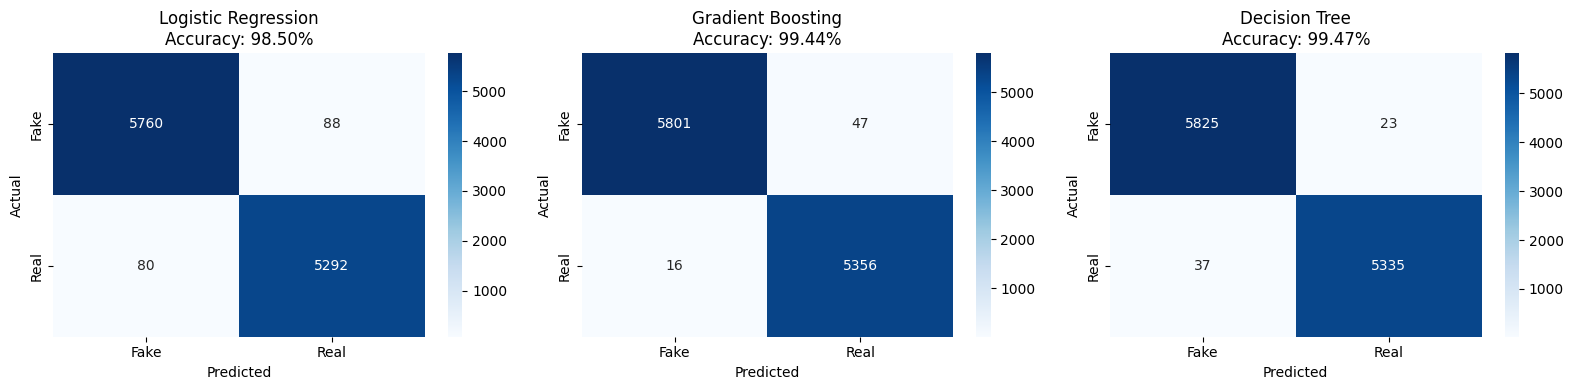

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": LR,
    "Gradient Boosting": GBC,
    "Decision Tree": DT,
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, model) in zip(axes, models.items()):
    pred = model.predict(xv_test)
    cm = confusion_matrix(y_test, pred)          # rows = actual, columns = predicted
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Fake", "Real"], yticklabels=["Fake", "Real"])
    ax.set_title(f"{name}\nAccuracy: {accuracy_score(y_test, pred)*100:.2f}%")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    print(f"\n{name}")
    print(cm)
plt.tight_layout()
plt.show()

In [ ]:
rows = []
for name, model in models.items():
    pred = model.predict(xv_test)
    rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, pred) * 100, 2),
        "Precision": round(precision_score(y_test, pred) * 100, 2),
        "Recall": round(recall_score(y_test, pred) * 100, 2),
        "F1-Score": round(f1_score(y_test, pred) * 100, 2),
    })
results = pd.DataFrame(rows)
print(results)

                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression     98.50      98.36   98.51     98.44
1    Gradient Boosting     99.44      99.13   99.70     99.42
2        Decision Tree     99.47      99.57   99.31     99.44


In [ ]:
def get_confidence(model, X):
    probs = model.predict_proba(X)               # shape: (n_samples, 2)
    labels = probs.argmax(axis=1)                # 0 = Fake, 1 = Real
    conf = probs.max(axis=1) * 100               # confidence in %
    return labels, conf

# Logistic Regression
lr_labels, lr_conf = get_confidence(LR, xv_test)
print("LR average confidence:", round(lr_conf.mean(), 2), "%")

# Gradient Boosting
gb_labels, gb_conf = get_confidence(GBC, xv_test)
print("GB average confidence:", round(gb_conf.mean(), 2), "%")

# Decision Tree
dt_labels, dt_conf = get_confidence(DT, xv_test)
print("DT average confidence:", round(dt_conf.mean(), 2), "%")

LR average confidence: 93.58 %
GB average confidence: 99.16 %
DT average confidence: 100.0 %


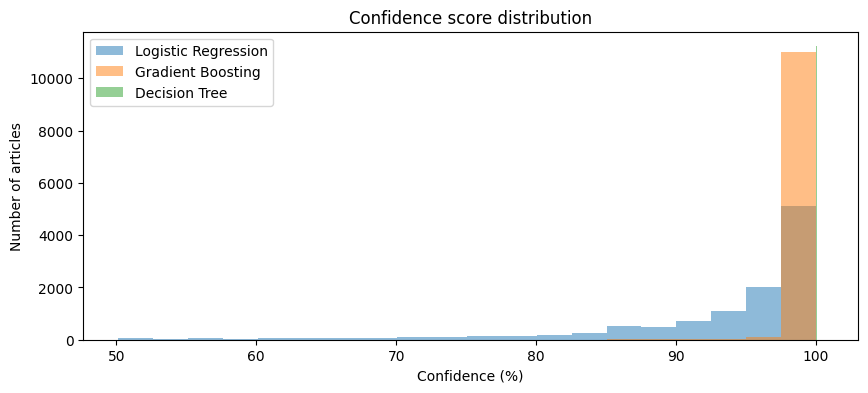

In [ ]:
plt.figure(figsize=(10, 4))
for name, conf in [("Logistic Regression", lr_conf),
                   ("Gradient Boosting", gb_conf),
                   ("Decision Tree", dt_conf)]:
    plt.hist(conf, bins=20, alpha=0.5, label=name)
plt.xlabel("Confidence (%)")
plt.ylabel("Number of articles")
plt.title("Confidence score distribution")
plt.legend()
plt.show()

In [ ]:
def predict_all(news_text):
    cleaned = wordopt(news_text)                 # your cleaning function (with the Reuters fix)
    vec = vectorization.transform([cleaned])
    for name, model in models.items():
        probs = model.predict_proba(vec)[0]
        label = "Real" if probs.argmax() == 1 else "Fake"
        print(f"{name:22s} -> {label:5s} | confidence: {probs.max()*100:.2f}%")

predict_all("21st Century Wire says As 21WIRE reported earlier this week, the unlikely  mishap  of two US Naval vessels straying into Iranian waters   just hours before the President s State of the Union speech, followed by the usual parade of arch-neocons coming on TV in real time to declare the incident as  an act of aggression  by Iran against the United States   is no mere coincidence.24 hours after the incident, the Iranians returned all 11 US sailors, unharmed and in good spirits. The only remaining casualty from this event was an incident of a common condition in Washington known as  Pre-Traumatic Stress Disorder    suffered by a certain US Senator was mortified by the uneventful outcome which followed Daniel McAdams Ron Paul Institute  The two US Navy riverine command boats intercepted in Iranian territorial waters yesterday were sent on their way along with the crew of 10 US sailors after brief detention on Iranian soil.According to news reports, the well-armed warships either suffered mechanical or navigational difficulties which caused them to enter Iranian territory (although it may well have been a game of cat-and-mouse to test the Iranian response). The US sailors were apparently treated well, enjoyed what appeared a decent meal in relaxed surroundings, and in the end apologized for the mistake and praised their treatment by the Iranians. Thanks to President Obama s policy shift on Iran toward engagement and away from isolationism, Secretary of State John Kerry was able to telephone his Iranian counterpart Mohammad Zarif and quickly defuse what just months ago would have been a far more serious situation.This should be a good-news story about the value of diplomacy and reducing tensions with adversaries, but Sen. John McCain (R-AZ) was having none of it. That Kerry expressed his appreciation to the Iranians for swiftly releasing the American sailors only showed the Obama Administration s  craven desire to preserve the dangerous Iranian nuclear deal at all costs evidently knows no limit,  said McCain in a press release.McCain was furious that  Obama administration officials seem to be falling over themselves to offer praise for Iran s graciousness  and was outraged that the Iranians dared interfere with the actions of US military vessels operating in Iranian waters.In the world of John McCain, only the United States has the right to national sovereignty. The US military has the right to act anywhere and everywhere and the rest of the world dare not raise a question.According to McCain,  sovereign immune naval vessels are exempt from detention, boarding, or search. Their crews are not subject to detention or arrest. Imagine the tune McCain would have been singing if a well-armed Iranian naval vessel had been spotted in US territorial waters off the coast of New York. Would he have so rigorously condemned any US interference in the actions of Iran s sovereign naval vessels?Leave it to some clever Twitterers to post an example of the difference between US and Iranian detention.")

Logistic Regression    -> Fake  | confidence: 97.59%
Gradient Boosting      -> Fake  | confidence: 99.54%
Decision Tree          -> Fake  | confidence: 100.00%


In [ ]:
import joblib
joblib.dump(LR, "model.pkl")
joblib.dump(vectorization, "tfidf.pkl")

['tfidf.pkl']

In [ ]:
print(LR.n_iter_)

[14]


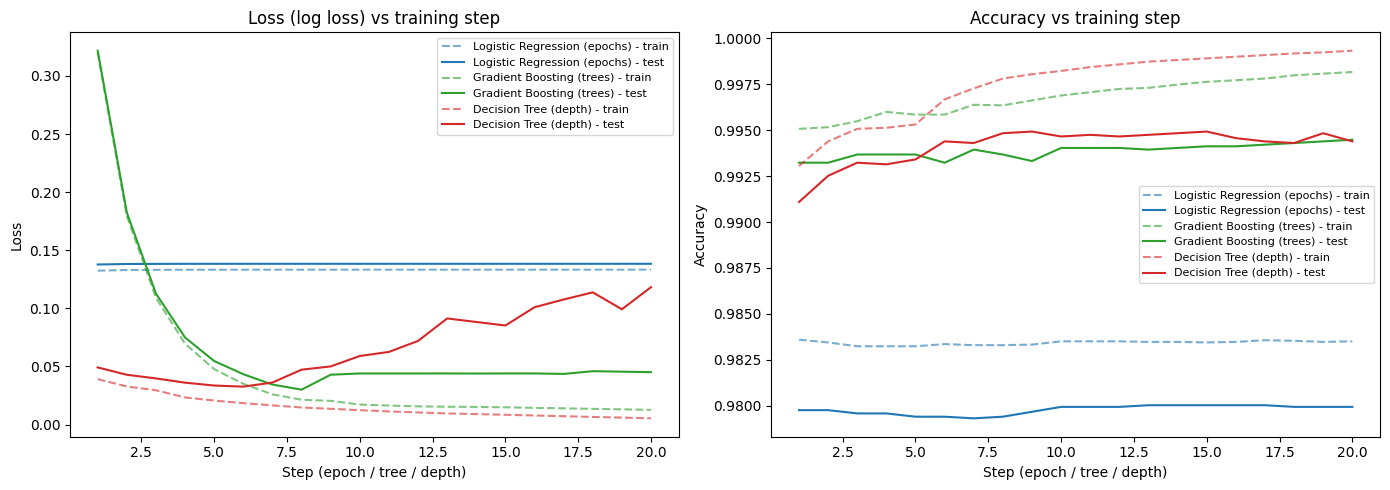

In [54]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import log_loss, accuracy_score

STEPS = 20
ytr, yte = np.asarray(y_train), np.asarray(y_test)
res = {}   # name -> dict of curves

# ---- 1. Logistic Regression (SGD): one epoch per step ----
sgd = SGDClassifier(loss="log_loss", random_state=42)
r = dict(tr_loss=[], te_loss=[], tr_acc=[], te_acc=[])
for _ in range(STEPS):
    sgd.partial_fit(xv_train, ytr, classes=np.array([0, 1]))
    r["tr_loss"].append(log_loss(ytr, sgd.predict_proba(xv_train)))
    r["te_loss"].append(log_loss(yte, sgd.predict_proba(xv_test)))
    r["tr_acc"].append(accuracy_score(ytr, sgd.predict(xv_train)))
    r["te_acc"].append(accuracy_score(yte, sgd.predict(xv_test)))
res["Logistic Regression (epochs)"] = r

# ---- 2. Gradient Boosting: one tree (stage) per step ----
gb = GradientBoostingClassifier(n_estimators=STEPS, learning_rate=0.5, random_state=42)
gb.fit(xv_train, ytr)
r = dict(tr_loss=[], te_loss=[], tr_acc=[], te_acc=[])
for ptr, pte in zip(gb.staged_predict_proba(xv_train), gb.staged_predict_proba(xv_test)):
    r["tr_loss"].append(log_loss(ytr, ptr)); r["te_loss"].append(log_loss(yte, pte))
    r["tr_acc"].append((ptr.argmax(1) == ytr).mean()); r["te_acc"].append((pte.argmax(1) == yte).mean())
res["Gradient Boosting (trees)"] = r

# ---- 3. Decision Tree: one extra level of depth per step ----
r = dict(tr_loss=[], te_loss=[], tr_acc=[], te_acc=[])
for depth in range(1, STEPS + 1):
    dt = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(xv_train, ytr)
    r["tr_loss"].append(log_loss(ytr, dt.predict_proba(xv_train)))
    r["te_loss"].append(log_loss(yte, dt.predict_proba(xv_test)))
    r["tr_acc"].append(dt.score(xv_train, ytr)); r["te_acc"].append(dt.score(xv_test, yte))
res["Decision Tree (depth)"] = r

# ---- Plot: solid = test, dashed = train ----
colors = {"Logistic Regression (epochs)": "tab:blue",
          "Gradient Boosting (trees)": "tab:green",
          "Decision Tree (depth)": "tab:red"}
x = range(1, STEPS + 1)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, r in res.items():
    c = colors[name]
    ax[0].plot(x, r["tr_loss"], "--", color=c, alpha=0.6, label=f"{name} - train")
    ax[0].plot(x, r["te_loss"], "-", color=c, label=f"{name} - test")
    ax[1].plot(x, r["tr_acc"], "--", color=c, alpha=0.6, label=f"{name} - train")
    ax[1].plot(x, r["te_acc"], "-", color=c, label=f"{name} - test")
ax[0].set_title("Loss (log loss) vs training step"); ax[0].set_xlabel("Step (epoch / tree / depth)"); ax[0].set_ylabel("Loss")
ax[1].set_title("Accuracy vs training step"); ax[1].set_xlabel("Step (epoch / tree / depth)"); ax[1].set_ylabel("Accuracy")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

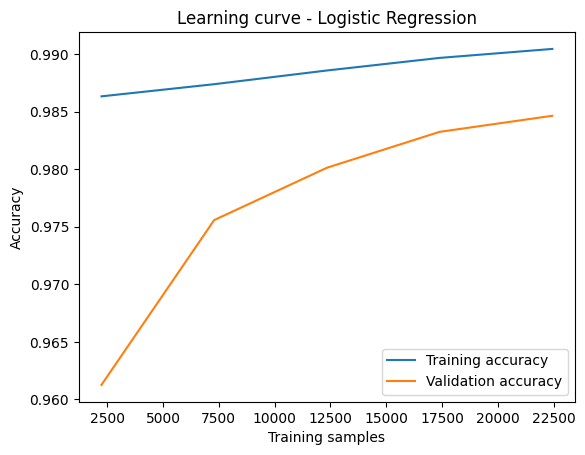

In [53]:
from sklearn.model_selection import learning_curve

sizes, train_sc, val_sc = learning_curve(
    LR, xv_train, y_train, cv=3, train_sizes=np.linspace(0.1, 1.0, 5), scoring="accuracy")

plt.plot(sizes, train_sc.mean(axis=1), label="Training accuracy")
plt.plot(sizes, val_sc.mean(axis=1), label="Validation accuracy")
plt.xlabel("Training samples"); plt.ylabel("Accuracy")
plt.title("Learning curve - Logistic Regression"); plt.legend(); plt.show()